# Map flux
## Make the same maps as the one presented in https://arxiv.org/pdf/2104.06855.pdf

### Import modules

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import Colormap
import pandas as pd

/home/tomas/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


### User parameters

In [2]:
incl = 48 * np.pi / 180.0
Nx = 32
f_Ny = 0.15 # Nyquist frequency (< 0.6)
#co = sqrt(8.d0*log(2.d0))       ! difference between sigma and theta!, theta = sigma*co

### Define some constants

In [3]:
h = 6.6260755e-27
m_e = 9.10938e-28
c = 2.99792458e10
e = 4.8032068e-10
kpc = 3.0856e21
distance = 3.8e3
convert = 206265e3/(distance*kpc) # image to angular size (mas)
# flux = 1.e26*(h/eV)/(4.0*np.pi*(distance*kpc)**2) # L[erg/s/erg] -> F[mJy]

### Define some useful functions

#### Funcion de potencia

In [4]:
def PowerFunction(E_ph, E, B, pitch_angle=np.pi/2):
    """
    Compute the emitted power as a function of energy, photon energy, magnetic field, and pitch angle.
    
    Parameters:
        E_ph (float or np.ndarray): Photon energy.
        E (float or np.ndarray): Energy of the particle.
        B (float): Magnetic field strength.
        pitch_angle (float): Pitch angle (default is pi/2).
    
    Returns:
        np.ndarray: Power emitted at the given photon energy.
    """
    # Define constants
    K = np.sqrt(3) * e**3 / (h * m_e * c**2)   #En el codigo fuente de agnpy es distinto
    Ec = (3 / (4 * np.pi)) * (e * h * B * np.sin(pitch_angle))/ (m_e**3 * c**5) *np.power(E,2)


    x = E_ph / Ec
        # Define an array for the Bessel integral approximation
    R = np.zeros_like(x)
    
    
    #Function G(x), (Aharonian+2010)
    term_1_num = 1.808 * np.power(x, 1 / 3)
    term_1_denom = np.sqrt(1 + 3.4 * np.power(x, 2 / 3))
    term_2_num = 1 + 2.21 * np.power(x, 2 / 3) + 0.347 * np.power(x, 4 / 3)
    term_2_denom = 1 + 1.353 * np.power(x, 2 / 3) + 0.217 * np.power(x, 4 / 3)
    R=term_1_num / term_1_denom * term_2_num / term_2_denom * np.exp(-x)

    # # Compute the emitted power
    P = K * B  * R* np.sin(pitch_angle)
    return P # [erg s^-1 erg^-1]


#### Coef. de Absorcion

In [5]:
from scipy.interpolate import interp1d
from scipy.misc import derivative
import scipy.integrate as integrate
def k_SSA(E_ph, eVec, neVec, bField):


    #we create a function that relates N with E, instead of 2 column table
    logne = interp1d(np.log(eVec), np.log(neVec), bounds_error=False, fill_value="extrapolate")
    def ne_e2(E_e):
        return np.exp(logne(np.log(E_e)))/(E_e*E_e)
    
    #We define the integrand, the function that we will integrate
    def integrand(loge, E_ph, bField):
        E_e = np.exp(loge)
        der_factor = derivative(logne, loge) - 2 #For a power law, the derivative should be (-p)
        if der_factor < 0. and der_factor > -10.:
            return E_e * PowerFunction(E_ph, E_e, bField) * E_e * ne_e2(E_e) * der_factor
        else:
            return 0.
    integral = integrate.quad(integrand, np.log(eVec[0]*1.1), np.log(eVec[-1]/1.1), args=(E_ph, bField))[0]
    return - h**3*c**2/ (8.*np.pi*E_ph*E_ph) * integral

#### Emisividad

In [6]:
def q(E_ph, B, N, E):
    integ = PowerFunction(E_ph, E, B)*N
    return np.trapz(integ, E)

#### Leo la distribucion de electrones

In [7]:
def get_Ne_E(filename='./../Code/Ne_cuts.dat'):
    # Read the data from the file
    data = pd.read_csv(filename, delim_whitespace=True, header=None, names=["energy", "N", "z_value"])
    
    # Extract unique energy and z_value
    energy = data["energy"].unique()
    z_value = data["z_value"].unique()
    
    # Create a pivot table for efficient mapping
    N = data.pivot(index="energy", columns="z_value", values="N").reindex(index=energy, columns=z_value).to_numpy()
    
    return energy, N

In [8]:
def get_j_alpha(nu, filename='./../Code/Em_Abs.dat'):
    # Read the data from the file
    data = pd.read_csv(filename, delim_whitespace=True, header=None, names=["energy", "emisivity", "absorption", "z_value"])
    
    # Find the energy associated with the given frequency nu
    energy_nu = h * nu * 1e9  # Convert frequency to energy
    
    # Filter the data for each z_value
    filtered_data = []
    for z in data["z_value"].unique():
        z_data = data[data["z_value"] == z]
        closest_index = (np.abs(z_data["energy"] - energy_nu)).idxmin()
        filtered_data.append(z_data.loc[closest_index, ["energy", "emisivity", "absorption"]])

    # Combine the filtered data into a DataFrame
    filtered_data = pd.DataFrame(filtered_data)
    return filtered_data['emisivity'], filtered_data['absorption']

In [9]:
# j, alpha= get_j_alpha(45.0)

# j = j.to_numpy()
# for i in values:
#     print(j[i-1], i)


In [10]:
def get_z_rz(filename='./../Code/quant_FF.dat'):
    """
    Load and return specific columns from the given file.

    Parameters:
        filename (str): Path to the file containing the data.

    Returns:
        tuple: Arrays of z, B, r_out, r_in, and delta_obs values.
    """
    return np.loadtxt(filename, usecols=(0, 1, 2, 3, 10), unpack=True)

In [109]:
def crossed_length(x, R_in, R_out):
        if abs(x) < abs(R_out) and abs(x) > abs(R_in):
                l = 2.0 * np.sqrt(R_out**2 - x**2)
        elif abs(x) <= abs(R_in):
                l = 2.0 * (np.sqrt(R_out**2 - x**2) - np.sqrt(abs(R_in**2 - x**2)))
        else:
                l = 0.0
        return l

In [187]:
#Esta interpola con q y alpha recien calculados
def Intensity_func_interp(Nx, nu, z_value):
    '''
    Function that returns the intensity for a given frequency at a given range of z, determined by the length of the input array.
    The function uses the k_SSA and q functions (absoption and emissivity) to calculate the intensity based on the input parameters.
    
    This function interpolates for any given value of z'''

    nu_h_eV = nu * h * 1e9
    if not hasattr(Intensity_func_interp, "_cached_data"):
        z, B, r_out, r_in, delta_obs = get_z_rz()
        E, N_df = get_Ne_E()
        N_df = pd.DataFrame(N_df)
        

        q_j = np.zeros(len(z))
        alpha = np.zeros(len(z))
        for columna in N_df.columns:
            q_j[columna]= q(nu_h_eV,B[columna],N_df[columna],E)
            alpha[columna]= k_SSA(nu_h_eV,E,N_df[columna],B[columna])
                                                                    
        Intensity_func_interp._cached_data = (z, B, r_out, r_in, delta_obs, E, N_df, q_j, alpha)
    else:
        z, B, r_out, r_in, delta_obs, E, N_df, q_j, alpha= Intensity_func_interp._cached_data
    
                       
    # Interpolations
    I_z_values = [delta_obs[idx]**3 * q_j[idx] / alpha[idx] for idx in range(len(z))]
    print( I_z_values)
    term_exp_values = [alpha[idx] / delta_obs[idx] for idx in range(len(z))]
    # Remove NaN values from I_z_values and term_exp_values
    valid_indices = ~np.isnan(I_z_values) & ~np.isnan(term_exp_values)
    I_z_values = np.array(I_z_values)[valid_indices]
    term_exp_values = np.array(term_exp_values)[valid_indices]
    z2 = np.array(z)[valid_indices]

    I_z = interp1d(np.log(z2), np.log(I_z_values), bounds_error=False, fill_value='extrapolate')
    term_exp = interp1d(np.log(z2), np.log(term_exp_values), bounds_error=False, fill_value='extrapolate')
    r_out_interp = interp1d(np.log(z), np.log(r_out), bounds_error=False, fill_value='extrapolate')
    r_in_interp = interp1d(np.log(z), np.log(r_in), bounds_error=False, fill_value='extrapolate')


    # Compute intensity
    # Compute intensity
    Step = np.exp(r_out_interp(np.log(z_value))) / Nx
    intensity_result = np.zeros(Nx)
    for i in range(Nx):
        x = Step * i
        tau = crossed_length(x, np.exp(r_in_interp(np.log(z_value))), np.exp(r_out_interp(np.log(z_value)))) * np.exp(term_exp(np.log(z_value))) / np.sin(incl)
        intensity_result[i] = np.exp(I_z(np.log(z_value))) * (1.0 - np.exp(-tau))
    return intensity_result
z = np.logspace(0, np.log10(1e19), 200)
I = np.zeros((len(z), Nx))
for i, z_value in enumerate(z):
    I[i]=Intensity_func_interp(Nx, 45.0, z_value)


/tmp/ipykernel_4674/3422124150.py:3: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data = pd.read_csv(filename, delim_whitespace=True, header=None, names=["energy", "N", "z_value"])
/tmp/ipykernel_4674/865538461.py:3: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return np.trapz(integ, E)
/home/tomas/.local/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/tmp/ipykernel_4674/835747678.py:15: DeprecationWarning: scipy.misc.derivative is deprecated in SciPy v1.10.0; and will be completely removed in SciPy v1.12.0. You may consider using findiff: https://github.com/maroba/findiff or numdifftools: https://github.com/pbrod/numdifftools
  der_factor = derivative(logne, loge) - 2 #For a power la

[np.float64(nan), np.float64(8.741977464601574e+57), np.float64(1.0718278908475206e+58), np.float64(1.3184955078276947e+58), np.float64(1.636953886170621e+58), np.float64(2.012916458587824e+58), np.float64(2.4780224414411994e+58), np.float64(3.054803256075064e+58), np.float64(3.76833509380957e+58), np.float64(4.6508246047319073e+58), np.float64(5.74256972399237e+58), np.float64(7.093747412686608e+58), np.float64(8.766742085360961e+58), np.float64(1.0839140483963196e+59), np.float64(1.3407577178811973e+59), np.float64(1.6592351861291884e+59), np.float64(2.054330906801884e+59), np.float64(2.544737004783771e+59), np.float64(3.1537577626958e+59), np.float64(3.910481989895062e+59), np.float64(4.8512182656403046e+59), np.float64(6.021332147673032e+59), np.float64(7.477502031744242e+59), np.float64(9.29058803742827e+59), np.float64(1.1549208591710718e+60), np.float64(1.4364229967538181e+60), np.float64(1.7874392006264375e+60), np.float64(2.2253393084405413e+60), np.float64(2.7718627697379622e

In [200]:
#Esta interpola las funciones de z
def Intensity_import_interp(Nx, nu, z_value):
    '''
    Function that returns the intensity for a given frequency at a given range of z, determined by the length of the input array.
    The function uses the values of absoption and emissivity imported from the function get_j_alpha that are closest to the specified energy
    (given by nu) to calculate the intensity based on the input parameters.
    
    This function interpolates for any given value of z'''

    # Retrieve data (cached to avoid redundant computation)
    if not hasattr(Intensity_import_interp, "_cached_data"):
        z, B, r_out, r_in, delta_obs = get_z_rz()
        E, N_df = get_Ne_E()
        N_df = pd.DataFrame(N_df, columns=z)
        j, alpha = get_j_alpha(nu)
        Intensity_import_interp._cached_data = (z, B, r_out, r_in, delta_obs, E, N_df, j, alpha)
    else:
        z, B, r_out, r_in, delta_obs, E, N_df, j, alpha = Intensity_import_interp._cached_data
    
    j=j.to_numpy()
    alpha=alpha.to_numpy()
    # Precompute constants
    nu_h_eV = nu * h * 1e9

    # Interpolations
    I_z_values = [delta_obs[idx]**3 * j[idx] / alpha[idx] for idx in range(len(z))]
    term_exp_values = [alpha[idx] / delta_obs[idx] for idx in range(len(z))]
    # Remove NaN values from I_z_values and term_exp_values
    valid_indices = ~np.isnan(I_z_values) & ~np.isnan(term_exp_values)
    I_z_values = np.array(I_z_values)[valid_indices]
    term_exp_values = np.array(term_exp_values)[valid_indices]
    z2 = np.array(z)[valid_indices]

    I_z = interp1d(np.log(z2), np.log(I_z_values), bounds_error=False, fill_value='extrapolate')
    term_exp = interp1d(np.log(z2), np.log(term_exp_values), bounds_error=False, fill_value='extrapolate')
    r_out_interp = interp1d(np.log(z), np.log(r_out), bounds_error=False, fill_value='extrapolate')
    r_in_interp = interp1d(np.log(z), np.log(r_in), bounds_error=False, fill_value='extrapolate')

    # Compute intensity
    Step = np.exp(r_out_interp(np.log(z_value))) / Nx
    intensity_result = np.zeros(Nx)
    for i in range(Nx):
        x = Step * i
        tau = crossed_length(x, np.exp(r_in_interp(np.log(z_value))), np.exp(r_out_interp(np.log(z_value)))) * np.exp(term_exp(np.log(z_value))) / np.sin(incl)
        intensity_result[i] = np.exp(I_z(np.log(z_value))) * (1.0 - np.exp(-tau))

    return intensity_result
z = np.logspace(0, np.log10(1e19), 200)
I = np.zeros((len(z), Nx))
for i, z_value in enumerate(z):
    I[i]=Intensity_import_interp(Nx, 45.0, z_value)

/tmp/ipykernel_4674/3422124150.py:3: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data = pd.read_csv(filename, delim_whitespace=True, header=None, names=["energy", "N", "z_value"])
/tmp/ipykernel_4674/2683494584.py:3: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data = pd.read_csv(filename, delim_whitespace=True, header=None, names=["energy", "emisivity", "absorption", "z_value"])
/tmp/ipykernel_4674/273818556.py:26: RuntimeWarning: invalid value encountered in scalar divide
  I_z_values = [delta_obs[idx]**3 * j[idx] / alpha[idx] for idx in range(len(z))]


In [164]:
#Esta calcula q_j y alpha y devuelve la intensidad para cada z
def Intensity_function(Nx, nu):
    '''
    Function that returns the intensity for a given frequency at a given range of z, determined by the length of the input array.
    The function uses the k_SSA and q functions (absoption and emissivity) to calculate the intensity based on the input parameters.
    
    This function does NOT interpolate for any given value of z'''
    # Retrieve data (cached to avoid redundant computation)
    if not hasattr(Intensity_function, "_cached_data"):
        z, B, r_out, r_in, delta_obs = get_z_rz()
        E, N_df = get_Ne_E()
        N_df = pd.DataFrame(N_df, columns=z)
        Intensity_function._cached_data = (z, B, r_out, r_in, delta_obs, E, N_df)
    else:
        z, B, r_out, r_in, delta_obs, E, N_df = Intensity_function._cached_data
    # Precompute constants
    nu_h_eV = nu * h * 1e9

    intensity_result = np.zeros((len(r_out), Nx))
    # Compute intensity
    for column in range(len(r_out)):
        
        Step = r_out[column] / Nx
        absorcion=k_SSA(nu_h_eV,E,N_df[z[column]],B[column])
        emisividad=q(nu_h_eV,B[column],N_df[z[column]],E)
        for i in range(Nx):
            x = Step * i
            tau = crossed_length(x, r_in[column], r_out[column]) * absorcion /(delta_obs[column]*np.sin(incl))
            intensity_result[column, i] = delta_obs[column]**3*(emisividad/ absorcion)*(1.0 - np.exp(-tau))
    return intensity_result
I=Intensity_function(Nx, 45.0)
I

/tmp/ipykernel_4674/3422124150.py:3: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data = pd.read_csv(filename, delim_whitespace=True, header=None, names=["energy", "N", "z_value"])
/home/tomas/.local/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/tmp/ipykernel_4674/835747678.py:15: DeprecationWarning: scipy.misc.derivative is deprecated in SciPy v1.10.0; and will be completely removed in SciPy v1.12.0. You may consider using findiff: https://github.com/maroba/findiff or numdifftools: https://github.com/pbrod/numdifftools
  der_factor = derivative(logne, loge) - 2 #For a power law, the derivative should be (-p)
/home/tomas/.local/lib/python3.10/site-packages/scipy/interpolate/_interpolate.py:479: RuntimeWarning: invalid value encountered in subtract
  slope = (y_hi - y_lo) / 

array([[           nan,            nan,            nan, ...,
                   nan,            nan,            nan],
       [9.95916040e+50, 9.96456800e+50, 9.98084403e+50, ...,
        4.21015625e+51, 3.46564066e+51, 2.47026182e+51],
       [1.02068644e+51, 1.02124065e+51, 1.02290874e+51, ...,
        4.31487129e+51, 3.55183808e+51, 2.53170216e+51],
       ...,
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [           nan,            nan,            nan, ...,
                   nan,            nan,            nan]])

In [201]:
I

array([[2.10769839e+24, 2.10769839e+24, 2.10769839e+24, ...,
        2.10769839e+24, 2.10769839e+24, 2.10769839e+24],
       [3.60680736e+24, 3.60680736e+24, 3.60680736e+24, ...,
        3.60680736e+24, 3.60680736e+24, 3.60680736e+24],
       [6.17216362e+24, 6.17216362e+24, 6.17216362e+24, ...,
        6.17216362e+24, 6.17216362e+24, 6.17216362e+24],
       ...,
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00]])

In [202]:
I_df=pd.DataFrame(I)

In [203]:
I_df


,0,1,2,3,4,5,6,7,8,9,...,22,23,24,25,26,27,28,29,30,31
0,2.107698e+24,2.107698e+24,2.107698e+24,2.107698e+24,2.107698e+24,2.107698e+24,2.107698e+24,2.107698e+24,2.107698e+24,2.107698e+24,...,2.107698e+24,2.107698e+24,2.107698e+24,2.107698e+24,2.107698e+24,2.107698e+24,2.107698e+24,2.107698e+24,2.107698e+24,2.107698e+24
1,3.606807e+24,3.606807e+24,3.606807e+24,3.606807e+24,3.606807e+24,3.606807e+24,3.606807e+24,3.606807e+24,3.606807e+24,3.606807e+24,...,3.606807e+24,3.606807e+24,3.606807e+24,3.606807e+24,3.606807e+24,3.606807e+24,3.606807e+24,3.606807e+24,3.606807e+24,3.606807e+24
2,6.172164e+24,6.172164e+24,6.172164e+24,6.172164e+24,6.172164e+24,6.172164e+24,6.172164e+24,6.172164e+24,6.172164e+24,6.172164e+24,...,6.172164e+24,6.172164e+24,6.172164e+24,6.172164e+24,6.172164e+24,6.172164e+24,6.172164e+24,6.172164e+24,6.172164e+24,6.172164e+24
3,1.056214e+25,1.056214e+25,1.056214e+25,1.056214e+25,1.056214e+25,1.056214e+25,1.056214e+25,1.056214e+25,1.056214e+25,1.056214e+25,...,1.056214e+25,1.056214e+25,1.056214e+25,1.056214e+25,1.056214e+25,1.056214e+25,1.056214e+25,1.056214e+25,1.056214e+25,1.056214e+25
4,1.807450e+25,1.807450e+25,1.807450e+25,1.807450e+25,1.807450e+25,1.807450e+25,1.807450e+25,1.807450e+25,1.807450e+25,1.807450e+25,...,1.807450e+25,1.807450e+25,1.807450e+25,1.807450e+25,1.807450e+25,1.807450e+25,1.807450e+25,1.807450e+25,1.807450e+25,1.807450e+25
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
196,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
197,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
198,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00


In [ ]:
#z, _, r_out, _, _ = get_z_rz()   #Correr cuando se use Intensity_function
x = np.linspace(0, 1, Nx)  # Assuming x is evenly spaced between -1 and 1 with Nx points
I_df.index = (z* np.sin(incl))*convert
I_df.columns = x* convert

In [205]:
I_df2 = I_df.fillna(0.0)
I_df2.max()

0.000000e+00    1.386005e+52
5.674670e-19    1.386005e+52
1.134934e-18    1.386005e+52
1.702401e-18    1.386005e+52
2.269868e-18    1.386005e+52
2.837335e-18    1.386005e+52
3.404802e-18    1.386005e+52
3.972269e-18    1.386005e+52
4.539736e-18    1.386005e+52
5.107203e-18    1.386005e+52
5.674670e-18    1.386005e+52
6.242137e-18    1.386005e+52
6.809604e-18    1.386005e+52
7.377071e-18    1.386005e+52
7.944538e-18    1.386005e+52
8.512005e-18    1.386005e+52
9.079472e-18    1.386005e+52
9.646939e-18    1.386005e+52
1.021441e-17    1.386005e+52
1.078187e-17    1.386005e+52
1.134934e-17    1.386005e+52
1.191681e-17    1.386005e+52
1.248427e-17    1.386005e+52
1.305174e-17    2.984927e+52
1.361921e-17    2.984927e+52
1.418668e-17    2.984927e+52
1.475414e-17    2.984927e+52
1.532161e-17    2.984927e+52
1.588908e-17    2.984927e+52
1.645654e-17    6.433751e+52
1.702401e-17    6.433751e+52
1.759148e-17    2.984927e+52
dtype: float64

200


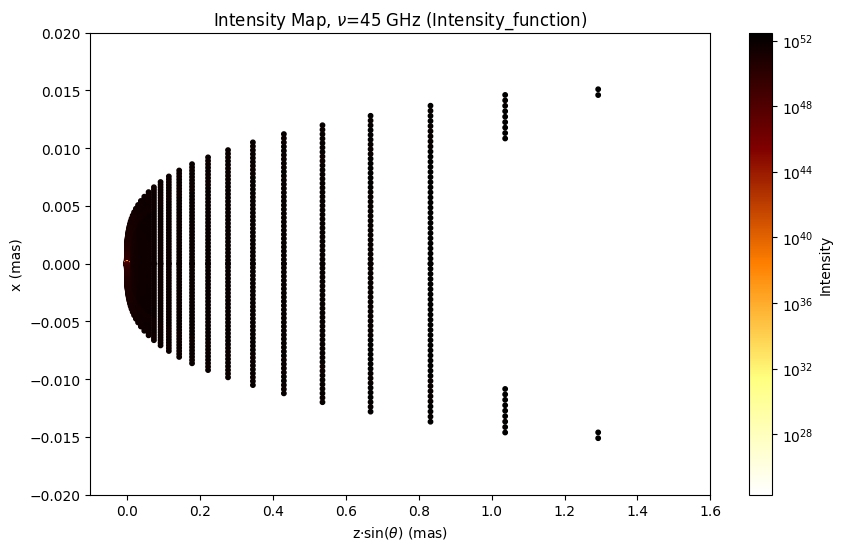

In [ ]:
# Assuming r_out is already defined and has the same length as the rows of I_df2
z_data, _, r_out, _, _ = get_z_rz()
r_out_interp = interp1d(np.log(z_data), np.log(r_out), bounds_error=False, fill_value='extrapolate')
#z=z_data           #Correr cuando se use Intensity_function
r_out_interp_data = np.exp(r_out_interp(np.log(z)))
# Create a meshgrid for the x and z coordinates
x_coords = r_out_interp_data*np.array(I_df2.columns)[:, None]
z_coords = np.array(I_df2.index)[:, None]
print(len(z_coords))
palette = plt.cm.afmhot_r
# Plot the data
plt.figure(figsize=(10, 6))
for i in range(Nx):
    sc = plt.scatter(z_coords, x_coords[i], c=I_df2[I_df2.columns[i]], norm=matplotlib.colors.LogNorm(), cmap=palette, s=10)
    sc = plt.scatter(z_coords, -x_coords[i], c=I_df2[I_df2.columns[i]], norm=matplotlib.colors.LogNorm(), cmap=palette, s=10)
plt.colorbar(sc, label='Intensity')
plt.xlabel(r'z$\cdot \sin(\theta)$ (mas)')
plt.ylabel('x (mas)')
plt.xlim(-0.1, 1.6)
plt.ylim(-0.02, 0.02)
plt.title(r'Intensity Map, $\nu$=45 GHz (Intensity_function)')
plt.show()



In [16]:
#Grafico de la luminosidad de brillo bs temperatura
#El cociente entre brillo del jet y contrajet nos da una idea del factor de lorentz del jet
#Las velocidades estimadas por el paper pueden usarse para las velocidades de la vaina y la espina del jet
#Plotear directamente el fmap (estoy ploteando el log de fmap_c, pero puedo plotear solo fmap sin convolucionar, deberia dar mas cercano a lo que produce el modelo, menos difuminado)


In [ ]:
def make_F_map(nu, Nx):
    I = Intensity(Nx, nu)  # Use the Intensity function to get I[z, x]
    z, r_z = get_z_rz()
    z = z[:140]
    r_z = r_z[:140]
    dz = z[1] - z[0]
    
    if dz * np.sin(incl) > 2.0 * r_z[-1] * np.cos(incl):  # Check for lateral projection
        x = np.linspace(0, r_z[-1], Nx) * convert
        dx = x[1] - x[0]
        print('Entramos a lateral_projection')
        y_map = z * np.sin(incl) * convert
        r_z_proj = r_z * convert
        L_map = np.ones((len(x), len(y_map))) * 0
        for j in range(len(y_map)):
            for i in range(len(x)):
                if x[i] < r_z_proj[j]:
                    L_map[i, j] = I[j, i] * dx
            # Correction factor for better conservation of intensity
            temp = np.sum(L_map[:, j])
            if temp > 0:
                L_map[:, j] = L_map[:, j] * np.sum(I[j, :]) / temp
    else:
        print('Entramos a faceon_projection')
        dy = 0.5 * r_z[0] * np.cos(incl) * convert  # delta_y < 2*r_j*cos(i) for all r_j
        dx = 0.5 * r_z[0] * convert
        y_max = (z[-1] * np.sin(incl) + r_z[-1] * np.cos(incl)) * convert
        x_max = r_z[-1] * convert
        Ny = int(y_max / dy)
        Nx = int(x_max / dx)
        print('Ny = ' + str(Ny))
        print('Nx = ' + str(Nx))
        y_map = np.linspace(0, y_max, Ny)
        x_map = np.linspace(0, x_max, Nx)

        L_map = np.zeros((np.size(x_map), np.size(y_map)))

        x_double = np.ones_like(L_map)
        y_double = np.ones_like(L_map)
        dx = x_map[1] - x_map[0]
        dy = y_map[1] - y_map[0]
        for j in range(len(y_map)):
            x_double[:, j] = x_map
        for i in range(len(x_map)):
            y_double[i, :] = y_map

        ellipses = []
        iy_start = 0
        L_tot = 0.0
        for iz in range(np.size(z)):
            print(iz)
            center = z[iz] * np.sin(incl) * convert
            a_semiaxis = r_z[iz] * convert
            b_semiaxis = r_z[iz] * np.cos(incl) * convert
            inv_area = np.power(np.pi * a_semiaxis * b_semiaxis, -1)
            # Equation: (x/a)² + ((y-z.sin(i))/b)² = 1
            ell = []
            for s in np.linspace(0, 2. * np.pi, 30):
                ell.append([a_semiaxis * np.cos(s), b_semiaxis * np.sin(s) + center])
            ellipses.append(ell)
            L_local = np.where(np.square(x_double / a_semiaxis) + np.square((y_double - center) / b_semiaxis) < 1.,
                               I[iz, :], 0) * min(dy * dx * inv_area, 0.5)
            renorm = 1. / (2. * np.sum(L_local) / np.sum(I[iz, :]))  # Renormalization factor to conserve intensity
            L_local = L_local * renorm
            L_map += L_local
            L_local = np.sum(L_local)
            L_tot += L_local
    print('L_proj/L_pre-proj = ' + str(2 * L_tot / np.sum(I)))

    return x_map, y_map, L_map


In [10]:
def Flux_mirror_map( x_map, L_map ):
    Nx = len(x_map)
    x_map22 = np.ones( 2*Nx )
    F_map = np.ones( (2*len(L_map[:, 0]), len(L_map[0, :])) )

    x_map22[:Nx] = -np.flip(x_map)
    x_map22[Nx:] = x_map
    F_map[:Nx, :] = np.flip(L_map, axis=0) * flux
    F_map[Nx:, :] = L_map*flux
    return x_map22, F_map

In [11]:
def Convolve_map( x_map, x_map22, y_map, F_map, sigma_x, sigma_y ):    
    # The number of points in the convolved map depends on the beam size and the size of the original map.

    # Extremes of the convolved map
    y_min_c = y_map[0] - 4. * sigma_y # 5 beams to the left of the jet base
    y_max_c = y_map[-1] + 4. * sigma_y # 5 beams to the right of the jet end point
    x_min_c = x_map22[0] - 3. * sigma_x # 3 beams above the jet lateral end point
    x_max_c = x_map[-1] + 3. * sigma_x # 3 beams below the jet lateral end point

    # Size of the convolved map
    ancho_x = x_max_c - x_min_c
    ancho_y = y_max_c - y_min_c 

    # Size of each cell of the convolved map
    Dx_c = f_Ny*sigma_x
    Dy_c = f_Ny*sigma_y

    # Number of cells of the convolved map
    Nx_c = int(ancho_x/Dx_c)
    Ny_c = int(ancho_y/Dy_c)

    # Position of the cells of the convolved map
    x_c = np.linspace( x_min_c, x_max_c, Nx_c)
    y_c = np.linspace( y_min_c, y_max_c, Ny_c)

    print('Dimension of the convolution grid: ' + str(Nx_c) + 'x' + str(Ny_c))
    
    F_map_c = np.ones((Nx_c, Ny_c))

    w_x = 0.5/sigma_x**2 # weight for x distance
    w_y = 0.5/sigma_y**2 # weight for y distance

    x_double = np.ones_like(F_map)
    y_double = np.ones_like(F_map)
    for j in range(len(y_map)):
        x_double[:, j] = x_map22
    for i in range(len(x_map22)):
        y_double[i, :] = y_map

    for i in range(Nx_c):
        for j in range(Ny_c):
            # Gaussian: (1/(2pi*sigma_x*sigma_y)) * exp(-((x-x_c)²/2.sigma_x² + (y-y_c)²/2.sigma_y²))
            gaussian = np.exp(-(np.square(x_double-x_c[i])*w_x + np.square(y_double-y_c[j])*w_y))
            F_map_c[i, j] = np.sum(F_map*gaussian)
            
    S_pre = np.sum(F_map)
    print('Pre-conv: S(GHz) = ' + str(S_pre) + ' mJy')
    # Gaussian beam -> exp(...)/(sigma*sqrt(2*pi)), both in x and y
    A_beam = 2 * np.pi * sigma_x * sigma_y     # = Gaussian normalization factor 
    A_cell = Dx_c * Dy_c              # cell sample size
    mJy_beam = A_cell/A_beam          # Transform mJy/beam -> mJy (for checks)
    S_post = np.sum(F_map_c) * mJy_beam
    print('Post-conv: S(GHz) = ' + str(S_post) + ' mJy')
    print('post/pre = ' + str(S_post/S_pre) )
    
    return x_c, y_c, F_map_c

In [12]:
def Make_spix_map( x_c, y_c, nu1, F_map1, nu2, F_map2, clip1, clip2):
    spix_map = np.empty((len(x_c), len(y_c))) 
    spix_map[:] = np.nan # Initialize to NaN
    log_nu2nu1 = np.log(nu2/nu1)

    for i in range(len(x_c)):
        for j in range(len(y_c)):
            print(F_map1[i,j] > clip1 and F_map2[i,j] > clip2 )
            if ( F_map1[i,j] > clip1 and F_map2[i,j] > clip2 ): 
                   spix_map[i,j] = np.log( F_map2[i,j]/F_map1[i,j] ) / log_nu2nu1
    return spix_map

## Make the intensity map at 43 GHz

In [13]:
nu_43 = 230.0 #43.0 # GHz
sigma_x, sigma_y = 0.01, 0.01 #0.31, 0.31 
x_map, y_map, L_map = make_F_map( nu_43, Nx )
# First mirror and convert to fluxes
x_map22, F_map = Flux_mirror_map( x_map, L_map)
x_c0, y_c0, F_map_c = Convolve_map( x_map, x_map22, y_map, F_map, sigma_x, sigma_y )

/tmp/ipykernel_12190/1725560376.py:4: UserWarning: loadtxt: input contained no data: "./../Code/SEDe_syn_cuts_ord.dat"
  data = np.loadtxt(fname).transpose()


IndexError: index 3 is out of bounds for axis 0 with size 0

In [13]:
#Temperatura de brillo es proporcional a la intensidad especifica
#EN el grafico del paper esta graficado en temperatura de brillo^1/2

In [20]:
from matplotlib.patches import Ellipse
# nice_fonts = {
#         # Use LaTeX to write all text
#         "text.usetex": False,
#         "font.family": 'serif',
#         # Use 10pt font in plots, to match 10pt font in document
#         "axes.labelsize": 16,
#         "font.size": 16,
#         "axes.linewidth":1,
#         "axes.titlesize":20,
#         # Make the legend/label fonts a little smaller
#         "legend.fontsize": 10,
#         "xtick.labelsize": 14,
#         "ytick.labelsize": 14,
# }
# matplotlib.rcParams.update(nice_fonts)


#plt.clf()
with plt.style.context(('classic')):
    fig, ax = plt.subplots(1, 1, figsize=(7.8, 6.6)) # proportion: 2.6/2.2
    #fig, ax = plt.subplots(1, 1) 
    ax.set_xlabel(r"$y~{\rm [mas]}$")
    ax.set_ylabel(r"$x~{\rm [mas]}$")
    ax.set_xlim([-0.05, 0.2])
    ax.set_ylim([-0.05, 0.05])
    palette = plt.cm.afmhot_r
    #cmap.set_label(r"$S_\nu$ [mJy beam$^{-1}$]")
    ticks = list(np.linspace(0.005,10,9))
    CS_conv = ax.contourf( y_c0, x_c0, (F_map_c), cmap=palette, levels = np.linspace(-5, 1, 100) )
    #Agregar contornos a (1, 1.4, 2, 2.8...)*3 mJy beam^-1 --> son 19? aprox
    obs_cont = (np.array([1, 1.4, 2, 2.8, 4, 5.6, 8, 10.2, 16, 20.4, 32, 40.8, 64, 81.6, 128, 163.2, 256])*.025)
    plot_cont = ax.contour(y_c0, x_c0, (F_map_c), linewidths=1, levels=obs_cont, extend="both", colors='dimgrey')

    el = Ellipse((0.15, -0.04), sigma_y, sigma_x, color='grey')
    ax.add_patch(el)

    ax.grid()
    plt.tight_layout()
    fig.colorbar( CS_conv, ticks=ticks ,label=r'$S_\nu~[{\rm Jy~beam}^{-1}]$')

In [21]:
print(np.min(np.log10(F_map_c)), np.max(np.log10(F_map_c)))
print(obs_cont)


-9.230591644656057 0.5850776078210622
[0.025 0.035 0.05  0.07  0.1   0.14  0.2   0.255 0.4   0.51  0.8   1.02
 1.6   2.04  3.2   4.08  6.4  ]


In [22]:
# Save plot
fig.savefig('Map_I_230GHz.pdf', bbox_inches='tight', dpi=300)
fig.savefig('Map_I_230GHz.png', bbox_inches='tight', dpi=100)

## Make the spix map between 22-43 GHz

In [156]:
sigma_x, sigma_y = 1.2, 1.2

nu1 = 22.0 # GHz
x_map, y_map, L_map2 = make_F_map( nu1, Nx )
x_map22, F_map1 = Flux_mirror_map( x_map, L_map2)
x_c, y_c, F_map_c1 = Convolve_map( x_map, x_map22, y_map, F_map1, sigma_x, sigma_y )

nu2 = 43.0 # GHz
x_map, y_map, L_map2 = make_F_map( nu2, Nx )
x_map22, F_map2 = Flux_mirror_map( x_map, L_map2)
x_c, y_c, F_map_c2 = Convolve_map( x_map, x_map22, y_map, F_map2, sigma_x, sigma_y )

(Ns, NSED_sy) = ( 750 ,  150 )
Entramos a faceon_projection
Ny = 9
Nx = 7
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
L_proj/L_pre-proj = 1.0000000000000004
Dimension of the convolution grid: 40x53
Pre-conv: S(GHz) = 1.627086747162803 mJy
Post-conv: S(GHz) = 1.540942980958461 mJy
post/pre = 0.9470564391514138
(Ns, NSED_sy) = ( 750 ,  150 )
Entramos a faceon_projection
Ny = 9
Nx = 7
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72


In [175]:
clip1, clip2 = 0.5, 0.5 # Clip below 10 rms
spix_map = Make_spix_map( x_c, y_c, nu1, F_map_c1, nu2, F_map_c2, clip1, clip2)

False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
Fals

In [176]:
plt.clf()
fig, ax = plt.subplots(1, 1, figsize=(8, 3)) # proportion: 16/6
ax.set_xlabel(r"$y$ [mas]")
ax.set_ylabel(r"$x$ [mas]")
ax.set_xlim([-3, 13])
ax.set_ylim([-3, 3])
palette  = plt.cm.jet 
ticks = [-2, -1.5, -1, -0.5, 0, 0.5, 1] 
levels = np.linspace(-0.1, 2, 100)
print(spix_map)
CS_conv = ax.contourf( y_c, x_c, spix_map, cmap=palette)# levels=levels)
# intensity contours at 22 GHz
obs_cont = np.array([1, 1.4, 2, 2.8, 4, 5.6, 8, 10.2, 16, 20.4, 32, 40.8, 64, 81.6, 128, 163.2, 256, 326.4, 512])*1.9 # HACERLOS EN GRIS
plot_cont = ax.contour( y_c, x_c, F_map_c1, levels=obs_cont, extend="both", colors='grey')

el = Ellipse((12, -2.3), sigma_y, sigma_x, color='grey')
ax.add_patch(el)

plt.tight_layout()
fig.colorbar(CS_conv, ticks=ticks)

[[nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]
 ...
 [nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]]


In [177]:
# Save plot
fig.savefig('Map_spix_22-43GHz_2_c.pdf', bbox_inches='tight')

## Make the spix map between 43-86 GHz

In [1]:
Nx0 = 64
sigma_x, sigma_y = 0.4, 0.2

nu1 = 43.0 # GHz
x_map, y_map, L_map2 = make_F_map( nu1, Nx0 )
x_map22, F_map1 = Flux_mirror_map( x_map, L_map2)
x_c, y_c, F_map_c1 = Convolve_map( x_map, x_map22, y_map, F_map1, sigma_x, sigma_y )

nu2 = 86.0 # GHz
x_map, y_map, L_map2 = make_F_map( nu2, Nx0 )
x_map22, F_map2 = Flux_mirror_map( x_map, L_map2)
x_c, y_c, F_map_c2 = Convolve_map( x_map, x_map22, y_map, F_map2, sigma_x, sigma_y )

NameError: name 'make_F_map' is not defined

In [79]:
clip1, clip2 = 0.05, 0.05 # Clip below 10 rms
spix_map = Make_spix_map( x_c, y_c, nu1, F_map_c1, nu2, F_map_c2, clip1, clip2)

False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
Fals

In [80]:
plt.clf()
fig, ax = plt.subplots(1, 1, figsize=(7.5, 4)) # proportion: 5/2
ax.set_xlabel(r"$y$ [mas]")
ax.set_ylabel(r"$x$ [mas]")
ax.set_xlim([-1, 4])
ax.set_ylim([-1, 1])
palette  = plt.cm.jet 
ticks = [-2, -1.5, -1, -0.5, 0, 0.5, 1] 
levels = np.linspace(-2., 0.5, 100)
CS_conv = ax.contourf( y_c, x_c, spix_map, cmap=palette, levels=levels)

# intensity contours at 43 GHz
obs_cont = np.array([1, 1.4, 2, 2.8, 4, 5.6, 8, 10.2, 16, 20.4, 32, 40.8, 64, 81.6, 128, 163.2, 256, 326.4, 512])*1.9 # HACERLOS EN GRIS
plot_cont = ax.contour( y_c, x_c, F_map_c1, levels=obs_cont, extend="both", colors='grey')

el = Ellipse((3.5, -0.7), sigma_y, sigma_x, color='grey')
ax.add_patch(el)

plt.tight_layout()
fig.colorbar(CS_conv, ticks=ticks)

In [81]:
# Save plot
fig.savefig('Map_spix_43-86GHz_2.pdf', bbox_inches='tight')